## **Задание 3. Градиентный спуск**

Выбрать ряд Тейлора, вычислить его значения с точностью $\varepsilon=0.0001$.
Стохастическим градиентным спуском найти веса ряда и сравнить с точной функцией.

Вариант 3: $e^x=1+x+x^2/2!+\ldots$. Возьмём $x\in[-1,1]$, шаг 0.1.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from math import factorial
from pathlib import Path

Path('results').mkdir(exist_ok=True)
x_start, x_end, dx = -1.0, 1.0, 0.1
eps = 0.0001
x_data = np.linspace(x_start, x_end, 21)

### Подготовить данные для обучения

Члены ряда считаем по формуле $t_{k+1}=t_kx/(k+1)$.
Останавливаемся, когда оценка всего оставшегося хвоста меньше $\varepsilon$.

In [2]:
y_data = np.ones_like(x_data)
term = np.ones_like(x_data)
n = 0
while True:
    next_term = term * x_data / (n + 1)
    tail = max(abs(next_term)) / (1 - max(abs(x_data)) / (n + 2))
    if tail < eps:
        break
    n += 1
    term = next_term
    y_data += term

print('Степень полинома:', n)
print('Оценка хвоста:', tail)
print('x:', x_data)
print('y:', y_data)

Степень полинома: 7
Оценка хвоста: 2.7901785714285717e-05
x: [-1.  -0.9 -0.8 -0.7 -0.6 -0.5 -0.4 -0.3 -0.2 -0.1  0.   0.1  0.2  0.3
  0.4  0.5  0.6  0.7  0.8  0.9  1. ]
y: [0.36785714 0.40655996 0.44932515 0.49658398 0.54881125 0.60653057
 0.67032003 0.74081822 0.81873075 0.90483742 1.         1.10517092
 1.22140276 1.34985881 1.49182468 1.64872117 1.82211835 2.01375116
 2.22553637 2.45959126 2.71825397]


### Начальные веса и модель

Обучаем $f_w(x)=w_0+w_1x+\ldots+w_nx^n$.
Точные коэффициенты этого ряда — $w_k=1/k!$.

In [3]:
w = np.zeros(n + 1)
X = np.column_stack([x_data**k for k in range(n + 1)])


def forward(x):
    return x @ w


def loss(x, y):
    return (forward(x) - y)**2


def gradient(x, y):
    return 2 * x * (forward(x) - y)


print('До обучения, x=1:', forward(X[-1]))

До обучения, x=1: 0.0


### Обучение

Как в примере задания: $w\leftarrow w-\eta\nabla L$, один объект на шаге.
Для вычислений заранее сохраним степени x; градиент остаётся тем же.

In [4]:
eta = 0.05
rng = np.random.default_rng(42)
loss_list = []
epoch_list = []

for epoch in range(150000):
    for i in rng.permutation(len(x_data)):
        grad = gradient(X[i], y_data[i])
        w -= eta * grad
    l = np.mean(loss(X, y_data))
    loss_list.append(l)
    epoch_list.append(epoch + 1)
    if (epoch + 1) % 30000 == 0:
        print('epoch:', epoch + 1, 'loss:', l)
    if l < 1e-17:
        break

print('После обучения, x=1:', forward(X[-1]))
print('Найденные веса:', w)
print('Точные веса:   ', [1 / factorial(k) for k in range(n + 1)])

epoch: 30000 loss: 4.7979776250654265e-11


epoch: 60000 loss: 1.1696899364400753e-12


epoch: 90000 loss: 2.4707888480786265e-14


epoch: 120000 loss: 5.901187072016697e-16


epoch: 150000 loss: 1.349173051617231e-17
После обучения, x=1: 2.7182539674003996
Найденные веса: [1.00000000e+00 1.00000003e+00 5.00000000e-01 1.66666393e-01
 4.16666669e-02 8.33387715e-03 1.38888932e-03 1.98105930e-04]
Точные веса:    [1.0, 1.0, 0.5, 0.16666666666666666, 0.041666666666666664, 0.008333333333333333, 0.001388888888888889, 0.0001984126984126984]


### Сравнение с точным решением

Максимальная ошибка: 2.7861058645495262e-05
Заданная точность: 0.0001


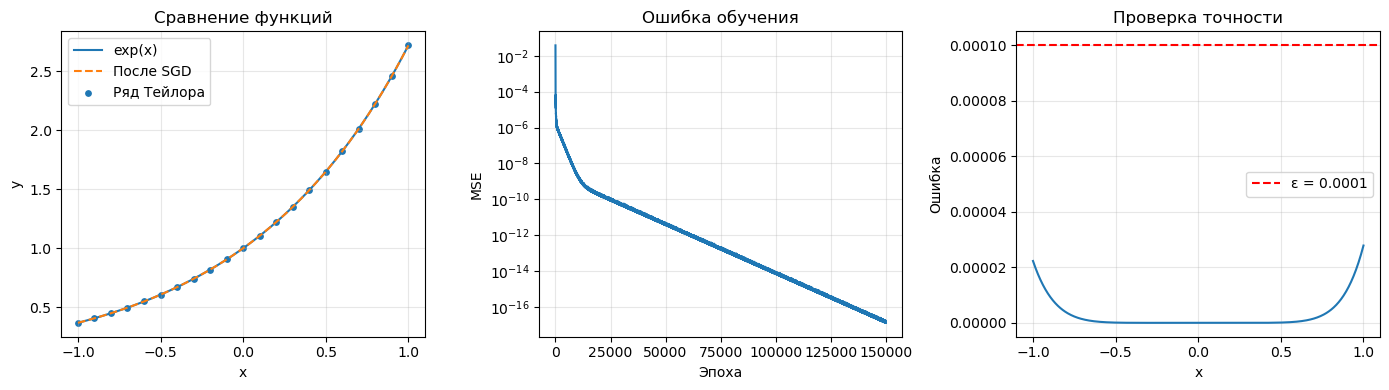

In [5]:
x = np.linspace(x_start, x_end, 401)
X_test = np.column_stack([x**k for k in range(n + 1)])
y = forward(X_test)
y_exact = np.exp(x)
error = max(abs(y - y_exact))
print('Максимальная ошибка:', error)
print('Заданная точность:', eps)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(x, y_exact, label='exp(x)')
ax[0].plot(x, y, '--', label='После SGD')
ax[0].scatter(x_data, y_data, s=15, label='Ряд Тейлора')
ax[0].set(xlabel='x', ylabel='y', title='Сравнение функций')
ax[0].legend()
ax[1].semilogy(epoch_list, loss_list)
ax[1].set(xlabel='Эпоха', ylabel='MSE', title='Ошибка обучения')
ax[2].plot(x, abs(y - y_exact))
ax[2].axhline(eps, color='red', linestyle='--', label='ε = 0.0001')
ax[2].set(xlabel='x', ylabel='Ошибка', title='Проверка точности')
ax[2].legend()
for a in ax:
    a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('results/gradient_descent.png', dpi=150)
plt.show()

np.savetxt('results/weights.csv', np.column_stack([np.arange(n+1), w,
           [1/factorial(k) for k in range(n+1)]]), delimiter=',',
           header='k,SGD,exact', comments='')
np.savetxt('results/predictions.csv', np.column_stack([x, y, y_exact]),
           delimiter=',', header='x,SGD,exp', comments='')
np.savez('results/data.npz', x=x_data, y=y_data, w=w,
         epochs=epoch_list, loss=loss_list, max_error=error)
assert error < eps

### Вывод

Стохастический градиентный спуск подобрал коэффициенты полинома.
На 401 проверочной точке ошибка относительно exp(x) меньше $10^{-4}$.
Для высоких степеней веса обучаются медленнее, поэтому проверяем и сами веса,
и значения функции. На графике видно уменьшение ошибки обучения.